# Project M2: Exploratory Data Analysis
## College Student Dropout Prediction
**Team:** Boyett and Etzler | **Date:** 23 October 2026

**Question:** Which information available at enrollment can support early outreach to students at risk of dropout?

This notebook examines the repository's 4,424 student records and all 36 predictors. The outcome remains **Dropout, Enrolled, or Graduate**; Enrolled is not relabeled as Dropout. M1 says a missed future dropout is more harmful than an unnecessary alert, while adviser workload still matters (Boyett and Etzler, *Proposal*, sec. 6). All associations below are descriptive, not causal.

**Reproduce:** Install the repository requirements, place `data.csv` in `data/raw/`, and run all cells from the repository root or `notebooks/`. A standalone copy also accepts `data.csv` beside the notebook; otherwise it downloads the same UCI dataset. The source file is not changed. Figures and all tabular results are generated by the code, not pasted manually.

**Evaluation limitation:** M2 explores the full file as requested. In M3, reserve a stratified 20% test set with seed 42 before fitting transformations; use cross-validation within the other 80%. Because this EDA has already seen all labels, that split is not a completely untouched external validation set. A new cohort would provide stronger confirmation.


In [51]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

paths = [Path('data/raw/data.csv'), Path('../data/raw/data.csv'), Path('data.csv')]
data_path = next((p for p in paths if p.exists()), None)
if data_path is None:
    url = ('https://archive.ics.uci.edu/static/public/697/'
           'predict+students+dropout+and+academic+success.zip')
    with urlopen(url, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
        raw = archive.read('data.csv')
else:
    raw = data_path.read_bytes()
df = pd.read_csv(io.BytesIO(raw), sep=';')
df.columns = df.columns.str.strip()
classes = ['Dropout', 'Enrolled', 'Graduate']
assert df.shape == (4424, 37)
assert set(df.Target.unique()) == set(classes)
print('Rows, columns:', df.shape)
print('CSV SHA-256:', hashlib.sha256(raw).hexdigest())
print('Exact duplicate rows:', df.duplicated().sum())
print('Python/pandas/numpy versions:')
import sys
print(sys.version.split()[0], pd.__version__, np.__version__)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 100)

Rows, columns: (4424, 37)
CSV SHA-256: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae
Exact duplicate rows: 0
Python/pandas/numpy versions:
3.13.15 3.0.6 2.5.4


## 1. Univariate analysis

Variable type follows meaning, not storage dtype. Course, nationality, qualification, occupation and application-mode integers are nominal codes. Binary indicators are categorical. Application order is ordinal; it is plotted as a discrete numeric variable but will be encoded categorically in M3 unless a monotonic effect is justified. Semester grades are real-valued despite the UCI table's integer label. Numeric-only correlation excludes all nominal/binary category codes and never assigns arbitrary numbers to Target.

The GDP field has no unit in the UCI metadata, so its axis explicitly says "source units unspecified" rather than inventing currency or percentage units. The source spelling `Nacionality` is retained. Definitions and coded missing values follow UCI's variable documentation (Realinho et al.).


          students  percent
Target                     
Dropout       1421    32.12
Enrolled       794    17.95
Graduate      2209    49.93


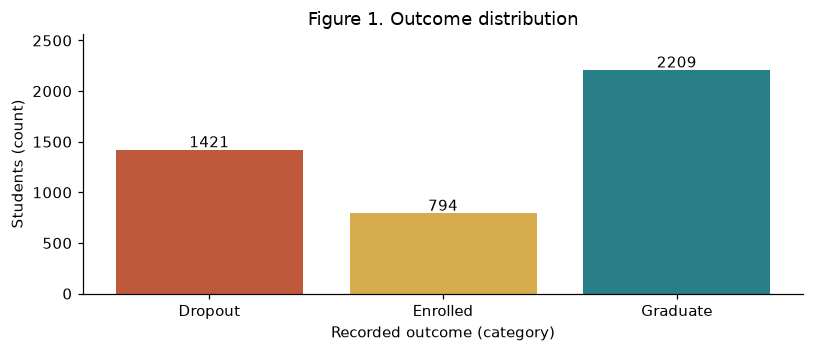

Interpretation: Graduate accounts for 49.93% of records, Dropout 32.12%, and Enrolled 17.95%; stratify the split and report class-specific metrics because a majority-class classifier would miss every dropout.


In [52]:
semester = [c for c in df if c.startswith('Curricular units')]
num = ['Application order', 'Previous qualification (grade)', 'Admission grade',
       'Age at enrollment'] + semester + ['Unemployment rate', 'Inflation rate', 'GDP']
cat = [c for c in df if c not in num + ['Target']]
assert len(num) == 19 and len(cat) == 17
assert set(num + cat + ['Target']) == set(df.columns)
units = {c: 'curricular units (count)' for c in semester}
for c in semester:
    if '(grade)' in c: units[c] = 'grade points (0-20)'
    elif '(evaluations)' in c: units[c] = 'evaluations (count)'
units.update({'Application order': 'preference rank (0-9)',
              'Previous qualification (grade)': 'grade points (0-200)',
              'Admission grade': 'grade points (0-200)',
              'Age at enrollment': 'years', 'Unemployment rate': 'percent',
              'Inflation rate': 'percent', 'GDP': 'source units unspecified'})
short = {c: c.replace('Curricular units ', 'CU ').replace('qualification', 'qual.')
         for c in num}
counts = df.Target.value_counts().reindex(classes)
print(pd.DataFrame({'students': counts, 'percent': counts / len(df) * 100}).round(2))
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.bar(classes, counts, color=['#be593c', '#d7ac4d', '#287f87'])
ax.set(title='Figure 1. Outcome distribution', xlabel='Recorded outcome (category)',
       ylabel='Students (count)')
for i, value in enumerate(counts): ax.text(i, value + 25, str(value), ha='center')
ax.set_ylim(0, counts.max() * 1.16)
plt.tight_layout(); plt.show()
print('Interpretation: Graduate accounts for 49.93% of records, Dropout 32.12%, '
      'and Enrolled 17.95%; stratify the split and report class-specific metrics '
      'because a majority-class classifier would miss every dropout.')

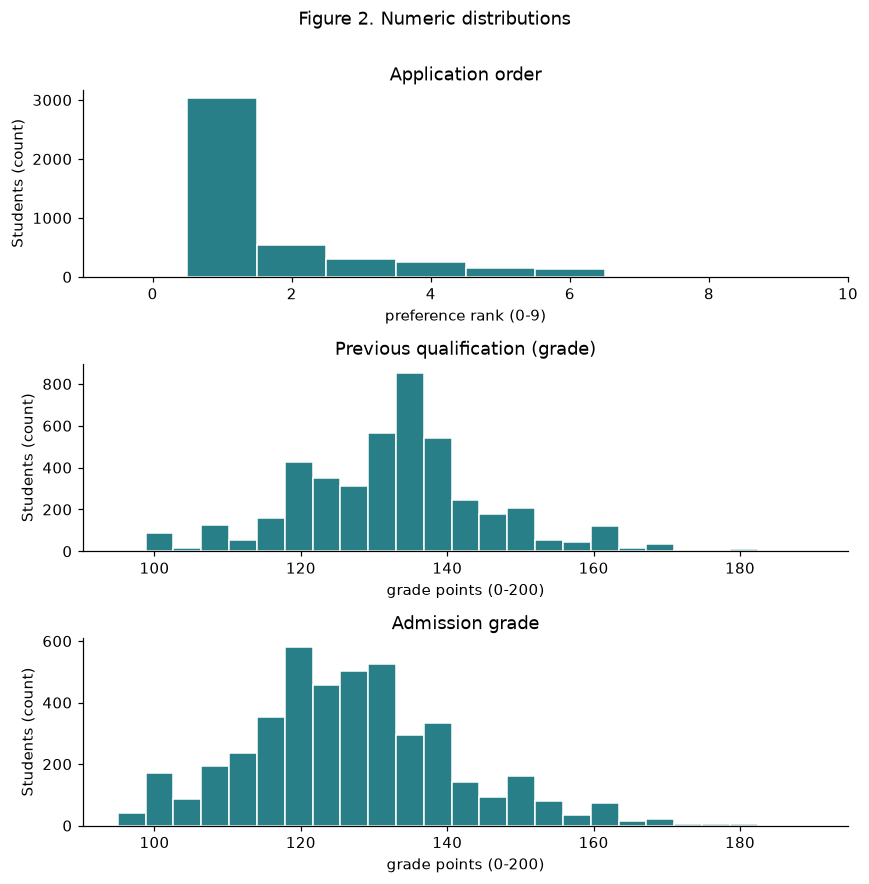

Application order: range=0 to 9; skew=1.88
Previous qualification (grade): range=95.0 to 190.0; skew=0.31
Admission grade: range=95.0 to 190.0; skew=0.53


In [53]:
selected = ['Application order', 'Previous qualification (grade)', 'Admission grade']
fig, axes = plt.subplots(len(selected), 1, figsize=(8, 2.65 * len(selected)))
for ax, c in zip(np.atleast_1d(axes), selected):
    values = df[c]
    bins = np.arange(values.min() - .5, values.max() + 1.5) if values.nunique() < 55 and (values % 1 == 0).all() else 25
    ax.hist(values, bins=bins, color='#287f87', edgecolor='white')
    ax.set(title=c, xlabel=units[c], ylabel='Students (count)')
fig.suptitle('Figure 2. Numeric distributions', y=1.005)
plt.tight_layout(); plt.show()
for c in selected:
    print(c + ': range=' + str(round(df[c].min(), 2)) + ' to ' + str(round(df[c].max(), 2))
          + '; skew=' + str(round(df[c].skew(), 2)))

**Application order:** The distribution concentrates on early preferences with a sparse upper tail; treat rank as ordinal/categorical rather than assuming equal linear effects.

**Previous qualification (grade):** Scores concentrate near the middle of the observed range with visible heaping; retain valid 0-200 scores and standardize using training data.

**Admission grade:** Scores have a central concentration and an upper tail; valid high scores are not grounds for removal, and training-only scaling is appropriate.

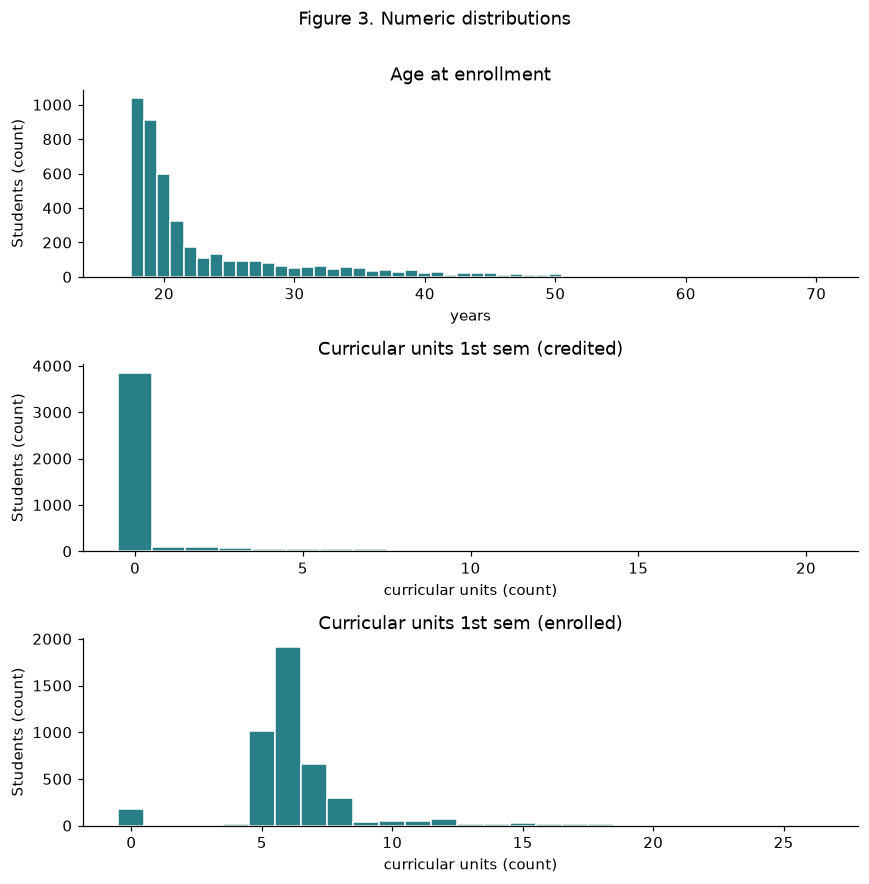

Age at enrollment: range=17 to 70; skew=2.05
Curricular units 1st sem (credited): range=0 to 20; skew=4.17
Curricular units 1st sem (enrolled): range=0 to 26; skew=1.62


In [54]:
selected = ['Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)']
fig, axes = plt.subplots(len(selected), 1, figsize=(8, 2.65 * len(selected)))
for ax, c in zip(np.atleast_1d(axes), selected):
    values = df[c]
    bins = np.arange(values.min() - .5, values.max() + 1.5) if values.nunique() < 55 and (values % 1 == 0).all() else 25
    ax.hist(values, bins=bins, color='#287f87', edgecolor='white')
    ax.set(title=c, xlabel=units[c], ylabel='Students (count)')
fig.suptitle('Figure 3. Numeric distributions', y=1.005)
plt.tight_layout(); plt.show()
for c in selected:
    print(c + ': range=' + str(round(df[c].min(), 2)) + ' to ' + str(round(df[c].max(), 2))
          + '; skew=' + str(round(df[c].skew(), 2)))

**Age at enrollment:** Most students are young with a long older-age tail; retain mature students and compare robust scaling with ordinary standardization.

**Curricular units 1st sem (credited):** The large zero spike and right tail are consistent with most students receiving no transferred credit; nonzero values are not automatic errors, but this semester snapshot is excluded from the enrollment baseline.

**Curricular units 1st sem (enrolled):** Counts concentrate around common course loads with a sparse upper tail; unusual loads may reflect program structure or credit histories, so do not delete them by IQR alone.

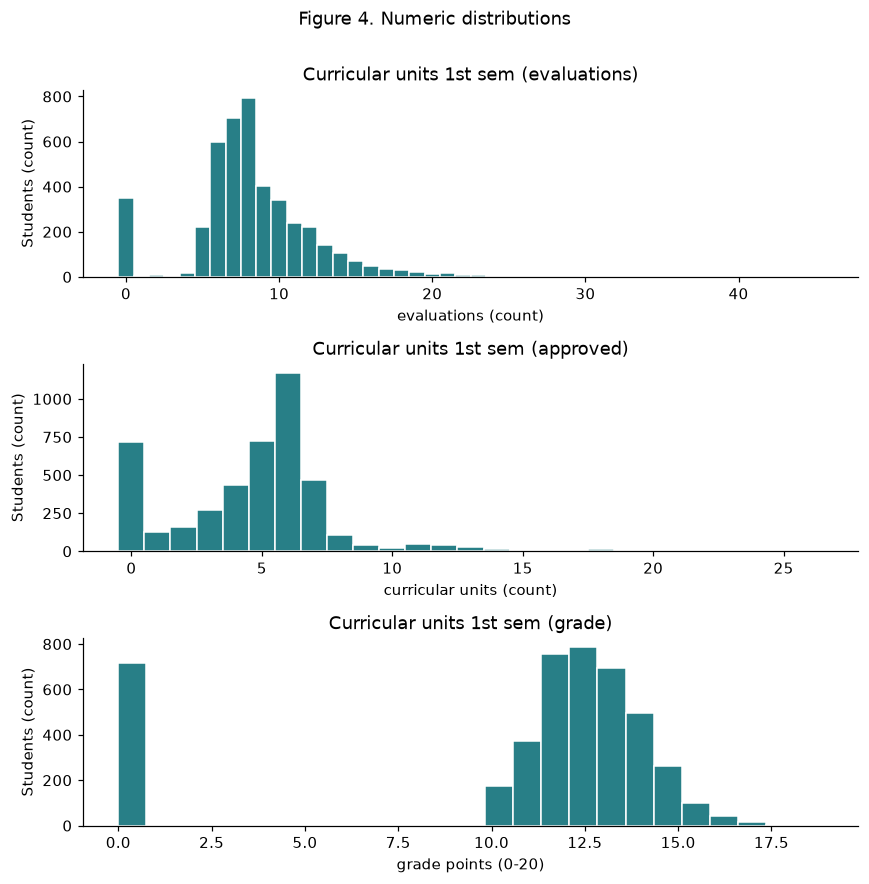

Curricular units 1st sem (evaluations): range=0 to 45; skew=0.98
Curricular units 1st sem (approved): range=0 to 26; skew=0.77
Curricular units 1st sem (grade): range=0.0 to 18.88; skew=-1.57


In [55]:
selected = ['Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)']
fig, axes = plt.subplots(len(selected), 1, figsize=(8, 2.65 * len(selected)))
for ax, c in zip(np.atleast_1d(axes), selected):
    values = df[c]
    bins = np.arange(values.min() - .5, values.max() + 1.5) if values.nunique() < 55 and (values % 1 == 0).all() else 25
    ax.hist(values, bins=bins, color='#287f87', edgecolor='white')
    ax.set(title=c, xlabel=units[c], ylabel='Students (count)')
fig.suptitle('Figure 4. Numeric distributions', y=1.005)
plt.tight_layout(); plt.show()
for c in selected:
    print(c + ': range=' + str(round(df[c].min(), 2)) + ' to ' + str(round(df[c].max(), 2))
          + '; skew=' + str(round(df[c].skew(), 2)))

**Curricular units 1st sem (evaluations):** The distribution has a long upper tail; evaluations can exceed enrolled units because counts measure different events, so retain plausible extremes for audit and exclude the semester snapshot.

**Curricular units 1st sem (approved):** A zero cluster and a cluster of successful course completions produce a mixed distribution; keep plausible counts for audit only because completion results leak future information.

**Curricular units 1st sem (grade):** A zero mass is separated from the positive-grade concentration; this mixed distribution is not a single normal population, and the field is excluded because grades are observed after enrollment.

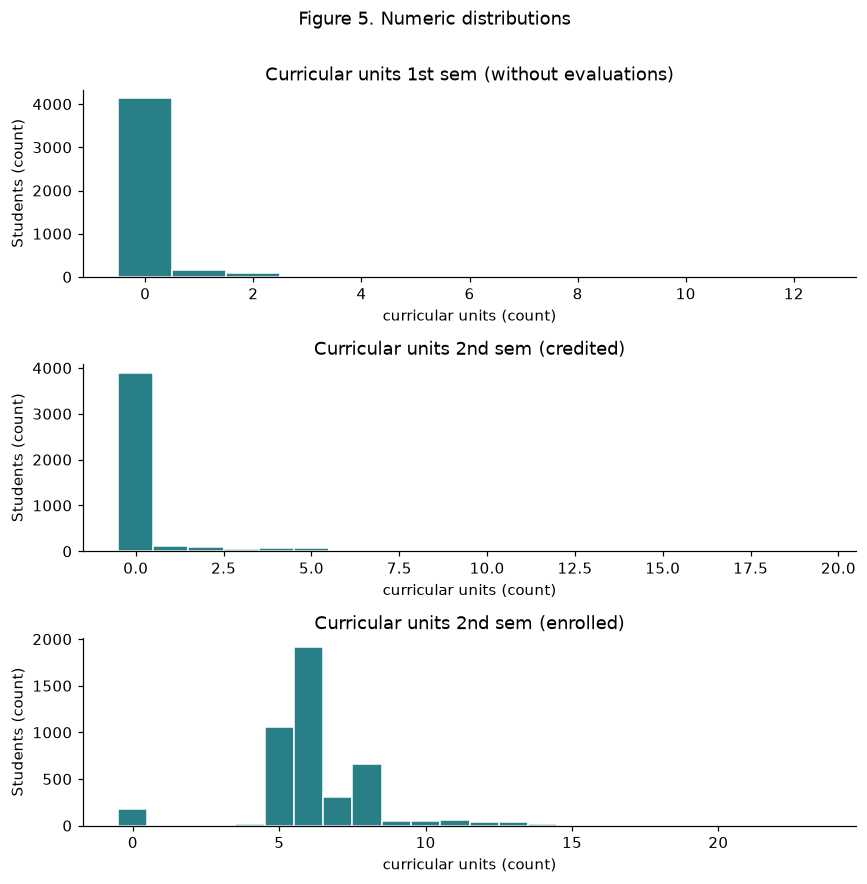

Curricular units 1st sem (without evaluations): range=0 to 12; skew=8.21
Curricular units 2nd sem (credited): range=0 to 19; skew=4.63
Curricular units 2nd sem (enrolled): range=0 to 23; skew=0.79


In [56]:
selected = ['Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)']
fig, axes = plt.subplots(len(selected), 1, figsize=(8, 2.65 * len(selected)))
for ax, c in zip(np.atleast_1d(axes), selected):
    values = df[c]
    bins = np.arange(values.min() - .5, values.max() + 1.5) if values.nunique() < 55 and (values % 1 == 0).all() else 25
    ax.hist(values, bins=bins, color='#287f87', edgecolor='white')
    ax.set(title=c, xlabel=units[c], ylabel='Students (count)')
fig.suptitle('Figure 5. Numeric distributions', y=1.005)
plt.tight_layout(); plt.show()
for c in selected:
    print(c + ': range=' + str(round(df[c].min(), 2)) + ' to ' + str(round(df[c].max(), 2))
          + '; skew=' + str(round(df[c].skew(), 2)))

**Curricular units 1st sem (without evaluations):** The distribution is dominated by zero with a sparse positive tail; an IQR rule can flag every positive value, so preserve these records and exclude this post-enrollment field.

**Curricular units 2nd sem (credited):** The large zero spike and right tail are consistent with most students receiving no transferred credit; nonzero values are not automatic errors, but this semester snapshot is excluded from the enrollment baseline.

**Curricular units 2nd sem (enrolled):** Counts concentrate around common course loads with a sparse upper tail; unusual loads may reflect program structure or credit histories, so do not delete them by IQR alone.

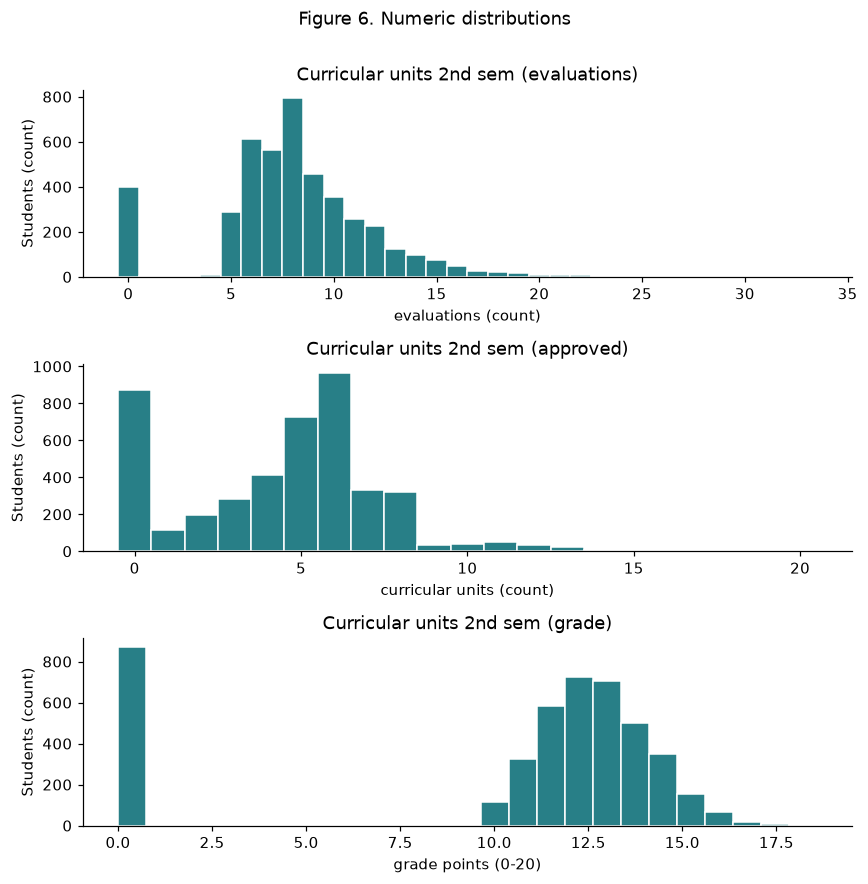

Curricular units 2nd sem (evaluations): range=0 to 33; skew=0.34
Curricular units 2nd sem (approved): range=0 to 20; skew=0.31
Curricular units 2nd sem (grade): range=0.0 to 18.57; skew=-1.31


In [57]:
selected = ['Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)']
fig, axes = plt.subplots(len(selected), 1, figsize=(8, 2.65 * len(selected)))
for ax, c in zip(np.atleast_1d(axes), selected):
    values = df[c]
    bins = np.arange(values.min() - .5, values.max() + 1.5) if values.nunique() < 55 and (values % 1 == 0).all() else 25
    ax.hist(values, bins=bins, color='#287f87', edgecolor='white')
    ax.set(title=c, xlabel=units[c], ylabel='Students (count)')
fig.suptitle('Figure 6. Numeric distributions', y=1.005)
plt.tight_layout(); plt.show()
for c in selected:
    print(c + ': range=' + str(round(df[c].min(), 2)) + ' to ' + str(round(df[c].max(), 2))
          + '; skew=' + str(round(df[c].skew(), 2)))

**Curricular units 2nd sem (evaluations):** The distribution has a long upper tail; evaluations can exceed enrolled units because counts measure different events, so retain plausible extremes for audit and exclude the semester snapshot.

**Curricular units 2nd sem (approved):** A zero cluster and a cluster of successful course completions produce a mixed distribution; keep plausible counts for audit only because completion results leak future information.

**Curricular units 2nd sem (grade):** A zero mass is separated from the positive-grade concentration; this mixed distribution is not a single normal population, and the field is excluded because grades are observed after enrollment.

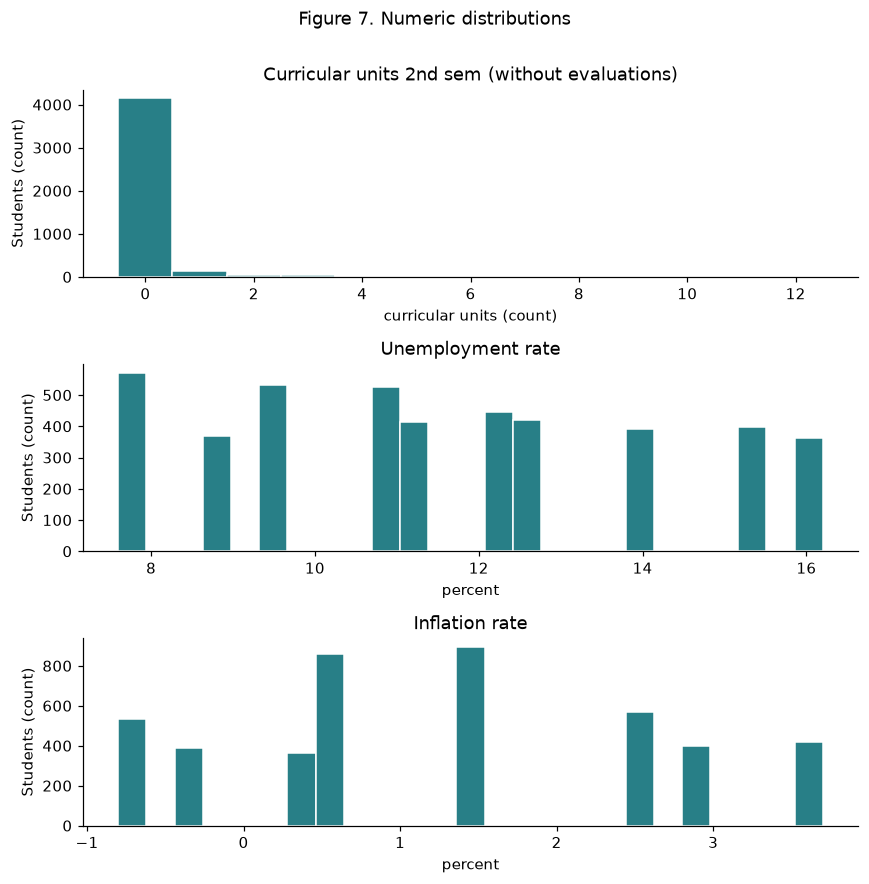

Curricular units 2nd sem (without evaluations): range=0 to 12; skew=7.27
Unemployment rate: range=7.6 to 16.2; skew=0.21
Inflation rate: range=-0.8 to 3.7; skew=0.25


In [58]:
selected = ['Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate']
fig, axes = plt.subplots(len(selected), 1, figsize=(8, 2.65 * len(selected)))
for ax, c in zip(np.atleast_1d(axes), selected):
    values = df[c]
    bins = np.arange(values.min() - .5, values.max() + 1.5) if values.nunique() < 55 and (values % 1 == 0).all() else 25
    ax.hist(values, bins=bins, color='#287f87', edgecolor='white')
    ax.set(title=c, xlabel=units[c], ylabel='Students (count)')
fig.suptitle('Figure 7. Numeric distributions', y=1.005)
plt.tight_layout(); plt.show()
for c in selected:
    print(c + ': range=' + str(round(df[c].min(), 2)) + ' to ' + str(round(df[c].max(), 2))
          + '; skew=' + str(round(df[c].skew(), 2)))

**Curricular units 2nd sem (without evaluations):** The distribution is dominated by zero with a sparse positive tail; an IQR rule can flag every positive value, so preserve these records and exclude this post-enrollment field.

**Unemployment rate:** Only ten distinct rates create multiple spikes rather than a smooth population distribution; shared macroeconomic values may identify entry cohorts, so verify release timing.

**Inflation rate:** Repeated annual values create several spikes, including negative rates; do not treat negative inflation as a data error and verify publication timing.

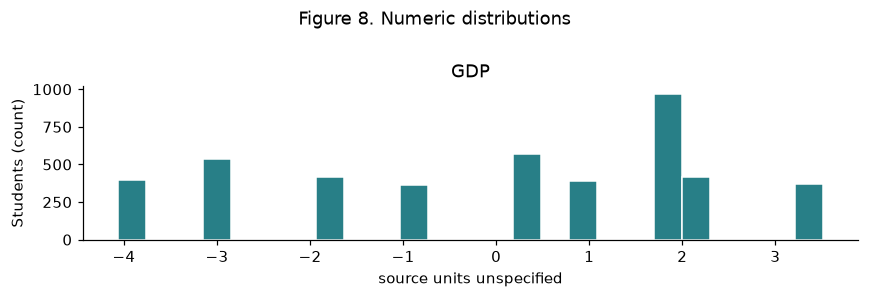

GDP: range=-4.06 to 3.51; skew=-0.39


In [59]:
selected = ['GDP']
fig, axes = plt.subplots(len(selected), 1, figsize=(8, 2.65 * len(selected)))
for ax, c in zip(np.atleast_1d(axes), selected):
    values = df[c]
    bins = np.arange(values.min() - .5, values.max() + 1.5) if values.nunique() < 55 and (values % 1 == 0).all() else 25
    ax.hist(values, bins=bins, color='#287f87', edgecolor='white')
    ax.set(title=c, xlabel=units[c], ylabel='Students (count)')
fig.suptitle('Figure 8. Numeric distributions', y=1.005)
plt.tight_layout(); plt.show()
for c in selected:
    print(c + ': range=' + str(round(df[c].min(), 2)) + ' to ' + str(round(df[c].max(), 2))
          + '; skew=' + str(round(df[c].skew(), 2)))

**GDP:** The repeated values show several separated concentrations; retain negative observations as potentially valid economic conditions, but exclude this field until units and timing are verified.

### Categorical frequencies: every level of every feature

The following tables count every observed code, including rare levels and coded unknowns. Codes are identifiers, not quantities; high occupation or course codes are not numeric outliers. For binary fields, 1 means yes and 0 means no, except attendance (1 daytime, 0 evening) and gender (1 male, 0 female). Qualification 34 means unknown; occupation 99 means blank, while 90 means other situation and 0 means student. Rare is defined here as fewer than 20 observations for descriptive review, not as a final preprocessing threshold.


In [60]:
c = 'Marital status'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Marital status
 code  students  percent
    1      3919    88.58
    2       379     8.57
    3         4     0.09
    4        91     2.06
    5        25     0.57
    6         6     0.14
Interpretation: Code 1 accounts for 88.6% of rows; 2 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [61]:
c = 'Application mode'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Application mode
 code  students  percent
    1      1708    38.61
    2         3     0.07
    5        16     0.36
    7       139     3.14
   10        10     0.23
   15        30     0.68
   16        38     0.86
   17       872    19.71
   18       124     2.80
   26         1     0.02
   27         1     0.02
   39       785    17.74
   42        77     1.74
   43       312     7.05
   44       213     4.81
   51        59     1.33
   53        35     0.79
   57         1     0.02
Interpretation: Code 1 accounts for 38.6% of rows; 6 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [62]:
c = 'Course'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Course
 code  students  percent
   33        12     0.27
  171       215     4.86
 8014       215     4.86
 9003       210     4.75
 9070       226     5.11
 9085       337     7.62
 9119       170     3.84
 9130       141     3.19
 9147       380     8.59
 9238       355     8.02
 9254       252     5.70
 9500       766    17.31
 9556        86     1.94
 9670       268     6.06
 9773       331     7.48
 9853       192     4.34
 9991       268     6.06
Interpretation: Code 9500 accounts for 17.3% of rows; 1 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [63]:
c = 'Daytime/evening attendance'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Daytime/evening attendance
 code  students  percent
    0       483    10.92
    1      3941    89.08
Interpretation: Code 1 accounts for 89.1% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [64]:
c = 'Previous qualification'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Previous qualification
 code  students  percent
    1      3717    84.02
    2        23     0.52
    3       126     2.85
    4         8     0.18
    5         1     0.02
    6        16     0.36
    9        11     0.25
   10         4     0.09
   12        45     1.02
   14         1     0.02
   15         2     0.05
   19       162     3.66
   38         7     0.16
   39       219     4.95
   40        40     0.90
   42        36     0.81
   43         6     0.14
Interpretation: Code 1 accounts for 84.0% of rows; 9 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [65]:
c = 'Nacionality'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Nacionality
 code  students  percent
    1      4314    97.51
    2         2     0.05
    6        13     0.29
   11         3     0.07
   13         1     0.02
   14         1     0.02
   17         1     0.02
   21         2     0.05
   22        13     0.29
   24         5     0.11
   25         2     0.05
   26        14     0.32
   32         1     0.02
   41        38     0.86
   62         2     0.05
  100         3     0.07
  101         2     0.05
  103         3     0.07
  105         2     0.05
  108         1     0.02
  109         1     0.02
Interpretation: Code 1 accounts for 97.5% of rows; 19 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [66]:
c = "Mother's qualification"
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Mother's qualification
 code  students  percent
    1      1069    24.16
    2        83     1.88
    3       438     9.90
    4        49     1.11
    5        21     0.47
    6         4     0.09
    9         8     0.18
   10         3     0.07
   11         3     0.07
   12        42     0.95
   14         2     0.05
   18         1     0.02
   19       953    21.54
   22         1     0.02
   26         1     0.02
   27         1     0.02
   29         3     0.07
   30         3     0.07
   34       130     2.94
   35         3     0.07
   36         3     0.07
   37      1009    22.81
   38       562    12.70
   39         8     0.18
   40         9     0.20
   41         6     0.14
   42         4     0.09
   43         4     0.09
   44         1     0.02
Interpretation: Code 1 accounts for 24.2% of rows; 19 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an expl

In [67]:
c = "Father's qualification"
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Father's qualification
 code  students  percent
    1       904    20.43
    2        68     1.54
    3       282     6.37
    4        39     0.88
    5        18     0.41
    6         2     0.05
    9         5     0.11
   10         2     0.05
   11        10     0.23
   12        38     0.86
   13         1     0.02
   14         4     0.09
   18         1     0.02
   19       968    21.88
   20         1     0.02
   22         4     0.09
   25         1     0.02
   26         2     0.05
   27         1     0.02
   29         3     0.07
   30         4     0.09
   31         1     0.02
   33         1     0.02
   34       112     2.53
   35         2     0.05
   36         8     0.18
   37      1209    27.33
   38       702    15.87
   39        20     0.45
   40         5     0.11
   41         2     0.05
   42         1     0.02
   43         2     0.05
   44         1     0.02
Interpretation: Code 37 accounts for 27.3% of rows; 24 levels have fewer than 20 students. Use categor

In [68]:
c = "Mother's occupation"
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Mother's occupation
 code  students  percent
    0       144     3.25
    1       102     2.31
    2       318     7.19
    3       351     7.93
    4       817    18.47
    5       530    11.98
    6        91     2.06
    7       272     6.15
    8        36     0.81
    9      1577    35.65
   10         4     0.09
   90        70     1.58
   99        17     0.38
  122         2     0.05
  123         7     0.16
  125         1     0.02
  131         1     0.02
  132         3     0.07
  134         4     0.09
  141         8     0.18
  143         3     0.07
  144         6     0.14
  151         3     0.07
  152         2     0.05
  153         2     0.05
  171         1     0.02
  173         1     0.02
  175         5     0.11
  191        26     0.59
  192         5     0.11
  193         4     0.09
  194        11     0.25
Interpretation: Code 9 accounts for 35.6% of rows; 20 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any r

In [69]:
c = "Father's occupation"
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Father's occupation
 code  students  percent
    0       128     2.89
    1       134     3.03
    2       197     4.45
    3       384     8.68
    4       386     8.73
    5       516    11.66
    6       242     5.47
    7       666    15.05
    8       318     7.19
    9      1010    22.83
   10       266     6.01
   90        65     1.47
   99        19     0.43
  101         1     0.02
  102         2     0.05
  103         4     0.09
  112         2     0.05
  114         1     0.02
  121         1     0.02
  122         2     0.05
  123         3     0.07
  124         1     0.02
  131         1     0.02
  132         1     0.02
  134         1     0.02
  135         3     0.07
  141         1     0.02
  143         1     0.02
  144         8     0.18
  151         2     0.05
  152         3     0.07
  153         1     0.02
  154         1     0.02
  161         1     0.02
  163         5     0.11
  171         8     0.18
  172         2     0.05
  174         1     0.02
  175

In [70]:
c = 'Displaced'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Displaced
 code  students  percent
    0      1998    45.16
    1      2426    54.84
Interpretation: Code 1 accounts for 54.8% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [71]:
c = 'Educational special needs'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Educational special needs
 code  students  percent
    0      4373    98.85
    1        51     1.15
Interpretation: Code 0 accounts for 98.8% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [72]:
c = 'Debtor'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Debtor
 code  students  percent
    0      3921    88.63
    1       503    11.37
Interpretation: Code 0 accounts for 88.6% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [73]:
c = 'Tuition fees up to date'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Tuition fees up to date
 code  students  percent
    0       528    11.93
    1      3896    88.07
Interpretation: Code 1 accounts for 88.1% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [74]:
c = 'Gender'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Gender
 code  students  percent
    0      2868    64.83
    1      1556    35.17
Interpretation: Code 0 accounts for 64.8% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [75]:
c = 'Scholarship holder'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

Scholarship holder
 code  students  percent
    0      3325    75.16
    1      1099    24.84
Interpretation: Code 0 accounts for 75.2% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


In [76]:
c = 'International'
freq = df[c].value_counts().sort_index()
print(c)
print(pd.DataFrame({'code': freq.index, 'students': freq.values,
                    'percent': (100 * freq.values / len(df)).round(2)}).to_string(index=False))
print(f'Interpretation: Code {freq.idxmax()} accounts for {100 * freq.max() / len(df):.1f}% '
      f'of rows; {(freq < 20).sum()} levels have fewer than 20 students. '
      'Use categorical encoding and handle unseen levels; estimate any rare-level '
      'pooling from training folds only, retaining unknown as an explicit category.')

International
 code  students  percent
    0      4314    97.51
    1       110     2.49
Interpretation: Code 0 accounts for 97.5% of rows; 0 levels have fewer than 20 students. Use categorical encoding and handle unseen levels; estimate any rare-level pooling from training folds only, retaining unknown as an explicit category.


## 2. Missingness: cells versus coded information gaps

A null-cell audit is necessary but insufficient. We check pandas nulls and whitespace-only text in every column, then examine UCI's explicit unknown/blank codes by outcome. Zero is not globally replaced: it is a valid binary value, may denote no course activity, and denotes student in occupation fields. Qualification 35/36 represent literacy categories, not missingness. Occupation 90 is "other situation," not blank.


                                        column  missing_n  missing_pct
                                Marital status          0          0.0
                              Application mode          0          0.0
                             Application order          0          0.0
                                        Course          0          0.0
                    Daytime/evening attendance          0          0.0
                        Previous qualification          0          0.0
                Previous qualification (grade)          0          0.0
                                   Nacionality          0          0.0
                        Mother's qualification          0          0.0
                        Father's qualification          0          0.0
                           Mother's occupation          0          0.0
                           Father's occupation          0          0.0
                               Admission grade          0          0.0
      

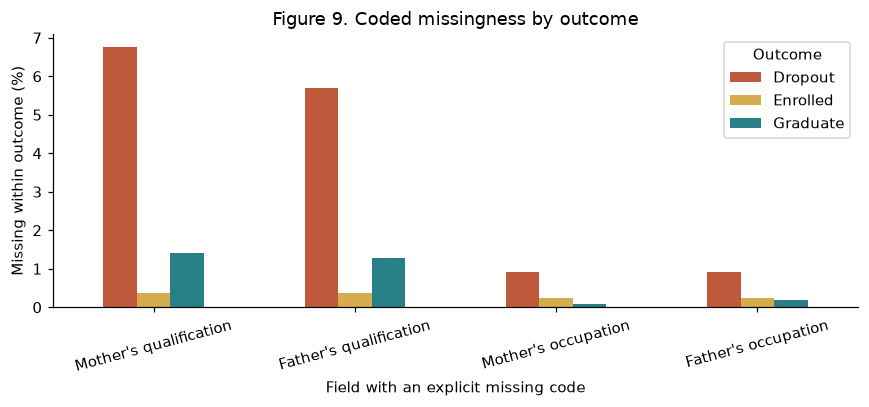

Interpretation: Unknown parental qualifications are more common among dropouts than graduates or enrolled students; preserve explicit unknown levels in M3 rather than dropping these students or replacing their category with the mode.


In [77]:
null = df.isna()
blank = df.astype('string').apply(lambda s: s.str.strip().eq('')).fillna(False)
cell_missing = null | blank
print(pd.DataFrame({'column': df.columns, 'missing_n': cell_missing.sum().values,
                    'missing_pct': cell_missing.mean().values * 100}).to_string(index=False))
print('Blank/null cells by target:')
print(cell_missing.groupby(df.Target).sum().sum(axis=1))
missing_codes = {"Mother's qualification": 34, "Father's qualification": 34,
                 "Mother's occupation": 99, "Father's occupation": 99}
missing_flags = pd.DataFrame({c: df[c].eq(k) for c, k in missing_codes.items()})
rows = []
for c in missing_flags:
    flag = missing_flags[c]
    rows.append({'field': c, 'n_missing': int(flag.sum()),
                 'missing_pct': 100 * flag.mean(),
                 'dropout_missing_pct': 100 * df.loc[flag, 'Target'].eq('Dropout').mean(),
                 'dropout_known_pct': 100 * df.loc[~flag, 'Target'].eq('Dropout').mean()})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print('Percent missing within each outcome:')
by_target = missing_flags.groupby(df.Target).mean().reindex(classes).T * 100
print(by_target.round(2).to_string())
print('Number of rows with any coded gap:', missing_flags.any(axis=1).sum())
print('Counts by number of coded gaps:')
print(missing_flags.sum(axis=1).value_counts().sort_index().to_string())
fig, ax = plt.subplots(figsize=(8, 3.8))
by_target.plot.bar(ax=ax, color=['#be593c', '#d7ac4d', '#287f87'])
ax.set(title='Figure 9. Coded missingness by outcome', xlabel='Field with an explicit missing code',
       ylabel='Missing within outcome (%)')
ax.tick_params(axis='x', rotation=15)
ax.legend(title='Outcome')
plt.tight_layout(); plt.show()
print('Interpretation: Unknown parental qualifications are more common among dropouts '
      'than graduates or enrolled students; preserve explicit unknown levels in M3 '
      'rather than dropping these students or replacing their category with the mode.')

**Conclusion:** All 37 columns have zero blank/null cells, so there is no varying null-cell indicator to test. That does not establish random missingness in the original collection: UCI says preprocessing had already addressed missing values and anomalies. The coded gaps are different: maternal-education unknowns have 73.85% dropout versus 30.86% among known records, and the within-target table also shows unequal missingness. These are descriptive associations inconsistent with treating the gaps as harmless random omissions, but they do not distinguish MAR from MNAR or establish causation. The occupation-blank groups have only 17 and 19 students, so their rates are unstable. Keep explicit unknown/blank levels, which already act as missingness indicators after one-hot encoding; do not also add duplicate binary columns. Any future imputer must be fitted only on training folds.


## 3. Outliers: screen, validate, decide

The 1.5-IQR rule screens each quantitative feature. It does not define an error. The table below gives the number flagged, observed range, and decision for every numeric feature. With zero IQR, ordinary nonzero counts can be flagged; do not trim these automatically. Nominal codes are excluded from the screen.


In [78]:
outlier_rows = []
for c in num:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    mask = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)
    outlier_rows.append({'feature': short[c], 'min': df[c].min(), 'max': df[c].max(),
                         'IQR': iqr, 'flagged_n': int(mask.sum())})
print(pd.DataFrame(outlier_rows).round(2).to_string(index=False))
checks = {}
for c in ['Previous qualification (grade)', 'Admission grade']:
    checks[c + ' outside 0-200'] = int((~df[c].between(0, 200)).sum())
checks['Age outside plausible adult-student range 15-100'] = int((~df['Age at enrollment'].between(15, 100)).sum())
checks['Application order outside documented 0-9'] = int((~df['Application order'].between(0, 9)).sum())
for s in ['1st', '2nd']:
    prefix = 'Curricular units ' + s + ' sem '
    checks[s + ' grades outside 0-20'] = int((~df[prefix + '(grade)'].between(0, 20)).sum())
    for k in ['credited', 'enrolled', 'evaluations', 'approved', 'without evaluations']:
        v = df[prefix + '(' + k + ')']
        checks[s + ' invalid ' + k + ' counts'] = int(((v < 0) | (v % 1 != 0)).sum())
    checks[s + ' approved > enrolled'] = int((df[prefix + '(approved)'] > df[prefix + '(enrolled)']).sum())
    checks[s + ' no-evaluation > enrolled'] = int((df[prefix + '(without evaluations)'] > df[prefix + '(enrolled)']).sum())
    zero = df[prefix + '(grade)'].eq(0)
    print(s, 'zero grades:', int(zero.sum()), '; zero grades with positive approved:',
          int((zero & df[prefix + '(approved)'].gt(0)).sum()))
print(pd.Series(checks, name='violations').to_string())
a = 'Curricular units 2nd sem (without evaluations)'
b = 'Curricular units 2nd sem (enrolled)'
suspect = df[a] > df[b]
print('Suspected consistency errors (zero-based source row index):')
audit = df.loc[suspect, [b, a, 'Target']].copy()
audit.columns = ['enrolled_units', 'without_evaluation_units', 'Target']
print(audit.to_string())


                         feature   min    max   IQR  flagged_n
               Application order  0.00   9.00  1.00        541
          Previous qual. (grade) 95.00 190.00 15.00        179
                 Admission grade 95.00 190.00 16.90         86
               Age at enrollment 17.00  70.00  6.00        441
           CU 1st sem (credited)  0.00  20.00  0.00        577
           CU 1st sem (enrolled)  0.00  26.00  2.00        424
        CU 1st sem (evaluations)  0.00  45.00  4.00        158
           CU 1st sem (approved)  0.00  26.00  3.00        180
              CU 1st sem (grade)  0.00  18.88  2.40        726
CU 1st sem (without evaluations)  0.00  12.00  0.00        294
           CU 2nd sem (credited)  0.00  19.00  0.00        530
           CU 2nd sem (enrolled)  0.00  23.00  2.00        369
        CU 2nd sem (evaluations)  0.00  33.00  4.00        109
           CU 2nd sem (approved)  0.00  20.00  4.00         44
              CU 2nd sem (grade)  0.00  18.57  2.58    

**Decisions and reasons:**

- **Age:** Keep ages 17-70, including IQR-flagged older students, as plausible real extremes. A mature entrant is not an invalid student; deleting older students would change the population we intend to support.
- **Previous and admission grades:** Keep flagged scores because the observed 95-190 values fall inside the documented 0-200 scale. Grade heaping is worth documenting but is not proof of fabrication.
- **Application order:** Keep the sparse ranks, including 9, because they lie within the documented 0-9 range; do not winsorize preference labels.
- **Credited and enrolled units, both semesters:** Keep nonnegative integer extremes as plausible credit-transfer or workload variation, subject to institutional confirmation. The file alone cannot certify each unusual record; exclude these snapshots from the enrollment baseline rather than deleting students.
- **Evaluations, both semesters:** Keep high counts provisionally. An evaluation count need not equal a count of distinct units; repeated assessments can explain higher totals. No evidence here establishes the extreme as an error.
- **Approved units, both semesters:** Keep zeros and high counts where the displayed consistency checks pass; zero successful units is a meaningful outcome, not a missing student.
- **Grades, both semesters:** Keep zeros for descriptive audit; the cross-check shows whether they coincide with no approved units. Do not replace these with an average grade. Positive values are within the 0-20 scale. Exclude all semester grades from the enrollment model.
- **Units without evaluations, both semesters:** Keep ordinary positive-tail observations, but flag three second-semester records as suspected consistency errors: rows 533, 1378 and 2931 have 12 versus 6, 7 versus 6, and 8 versus 5 units without evaluations versus units enrolled. Under a same-semester subset interpretation these are inconsistent, so they should not be accepted as ordinary real extremes. Confirm the source counting definition before correcting them; retain the raw values and exclude this field from the enrollment model. First-semester records pass this check. No negative/fractional-count error was detected.
- **Unemployment, inflation and GDP:** Keep observed values in the raw data; negative inflation and GDP indicators are economically plausible, not automatic errors. Their repeated levels reflect shared conditions rather than independent student measurements. Quarantine the macroeconomic fields from the baseline until release timing is verified; GDP also needs unit clarification.

The range checks found no invalid grade, rank or negative/fractional count, but the three second-semester subset violations are suspected data errors or definition mismatches that remain unresolved. "Keep provisionally" is a reasoned treatment decision, not a claim that institutional records were individually verified. Preserve the original rows, fit scalers within training folds, and investigate confirmed invalid values before any correction.


## 4. Bivariate analysis

For quantitative predictors, compare medians by the three nominal target groups and show boxplots for the three core continuous enrollment variables. For categorical predictors, show counts and **within-category outcome percentages** for every level. These denominators answer how outcomes vary within a category; they do not confuse the frequency of a category with its risk. Small groups remain descriptive. The numeric correlation matrix appears in Section 5; Target is never encoded as 0/1/2 for Pearson correlation.


Numeric medians by outcome (units as in Section 1):
Target                            Dropout  Enrolled  Graduate
Application order                    1.00      1.00      1.00
Previous qual. (grade)             133.10    130.00    133.10
Admission grade                    123.60    124.10    127.40
Age at enrollment                   23.00     20.00     19.00
CU 1st sem (credited)                0.00      0.00      0.00
CU 1st sem (enrolled)                6.00      6.00      6.00
CU 1st sem (evaluations)             8.00      9.00      8.00
CU 1st sem (approved)                2.00      5.00      6.00
CU 1st sem (grade)                  10.93     12.00     13.00
CU 1st sem (without evaluations)     0.00      0.00      0.00
CU 2nd sem (credited)                0.00      0.00      0.00
CU 2nd sem (enrolled)                6.00      6.00      6.00
CU 2nd sem (evaluations)             7.00      9.00      8.00
CU 2nd sem (approved)                0.00      4.00      6.00
CU 2nd sem (grade)

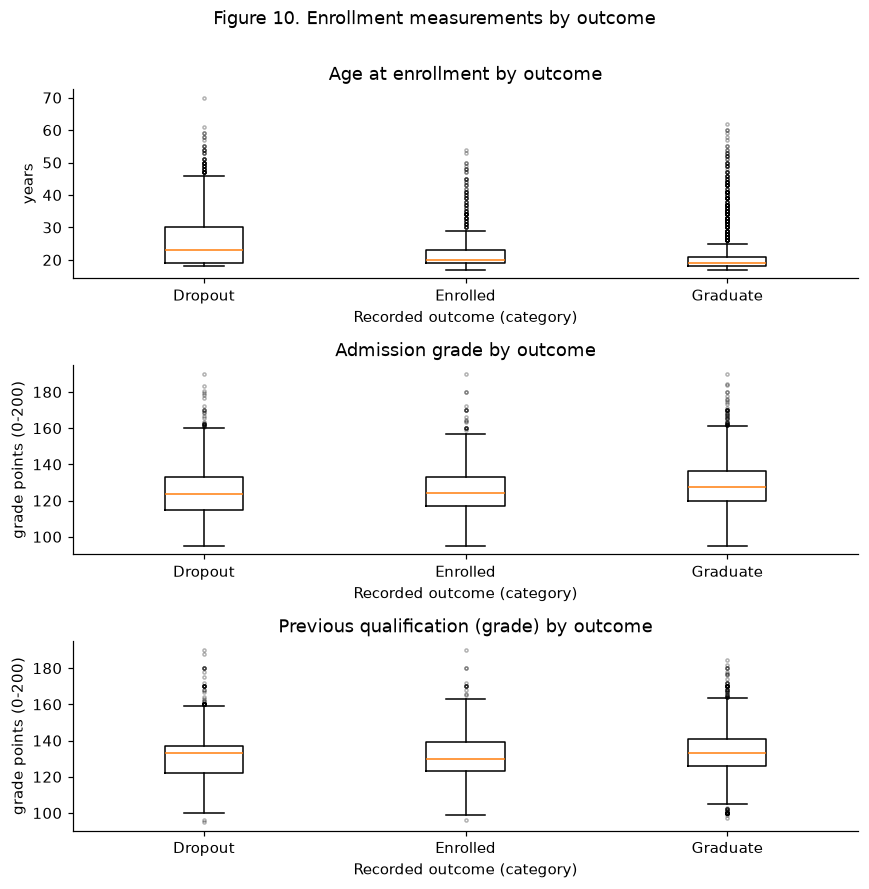

Age: Medians are 23 for Dropout, 20 for Enrolled, and 19 for Graduate; retain age and test nonlinear effects without treating this association as causal.
Admission grade: The distributions overlap despite group differences; retain the score as a candidate, but no cutoff cleanly separates outcomes.
Previous qualification grade: The groups overlap substantially; evaluate incremental predictive value within training cross-validation.


In [79]:
print('Numeric medians by outcome (units as in Section 1):')
medians = df.groupby('Target')[num].median().reindex(classes).T
medians.index = [short[c] for c in medians.index]
print(medians.round(2).to_string())
selected = ['Age at enrollment', 'Admission grade', 'Previous qualification (grade)']
fig, axes = plt.subplots(3, 1, figsize=(8, 8))
for ax, c in zip(axes, selected):
    ax.boxplot([df.loc[df.Target.eq(t), c] for t in classes], tick_labels=classes,
               flierprops={'markersize': 2, 'alpha': .3})
    ax.set(title=c + ' by outcome', xlabel='Recorded outcome (category)', ylabel=units[c])
fig.suptitle('Figure 10. Enrollment measurements by outcome', y=1.005)
plt.tight_layout(); plt.show()
print('Age: Medians are 23 for Dropout, 20 for Enrolled, and 19 for Graduate; '
      'retain age and test nonlinear effects without treating this association as causal.')
print('Admission grade: The distributions overlap despite group differences; '
      'retain the score as a candidate, but no cutoff cleanly separates outcomes.')
print('Previous qualification grade: The groups overlap substantially; '
      'evaluate incremental predictive value within training cross-validation.')

The full median table includes every numeric feature. Semester completion and grade differences can describe outcomes, but they cannot justify using those features at enrollment. Application-order medians can conceal category differences, so the additional grouped table below keeps its discrete levels. Repeated economic indicators may confound cohort differences and require temporal validation before use.


In [80]:
c = 'Application order'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Application order: counts and within-category percentages
Target             Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Application order                                                                            
0                        0         0         1     1          0.0           0.0         100.0
1                     1053       565      1408  3026         34.8          18.7          46.5
2                      150        96       301   547         27.4          17.6          55.0
3                       76        60       173   309         24.6          19.4          56.0
4                       58        31       160   249         23.3          12.4          64.3
5                       53        25        76   154         34.4          16.2          49.4
6                       31        16        90   137         22.6          11.7          65.7
9                        0         1         0     1          0.0         100.0           0.0
In

In [81]:
c = 'Marital status'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Marital status: counts and within-category percentages
Target          Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Marital status                                                                            
1                  1184       720      2015  3919         30.2          18.4          51.4
2                   179        52       148   379         47.2          13.7          39.1
3                     1         2         1     4         25.0          50.0          25.0
4                    42        16        33    91         46.2          17.6          36.3
5                    11         3        11    25         44.0          12.0          44.0
6                     4         1         1     6         66.7          16.7          16.7
Interpretation: Among levels with at least 20 students, observed dropout rates range from 30.2% (code 1) to 47.2% (code 2). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal

In [82]:
c = 'Application mode'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Application mode: counts and within-category percentages
Target            Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Application mode                                                                            
1                     345       300      1063  1708         20.2          17.6          62.2
2                       2         0         1     3         66.7           0.0          33.3
5                       2         8         6    16         12.5          50.0          37.5
7                      85         7        47   139         61.2           5.0          33.8
10                      3         0         7    10         30.0           0.0          70.0
15                      5        10        15    30         16.7          33.3          50.0
16                      5         8        25    38         13.2          21.1          65.8
17                    256       159       457   872         29.4          18.2          52.4
18           

In [83]:
c = 'Course'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Course: counts and within-category percentages
Target  Dropout  Enrolled  Graduate    n  Dropout_pct  Enrolled_pct  Graduate_pct
Course                                                                           
33            8         3         1   12         66.7          25.0           8.3
171          82        37        96  215         38.1          17.2          44.7
8014         71        21       123  215         33.0           9.8          57.2
9003         86        37        87  210         41.0          17.6          41.4
9070         51        42       133  226         22.6          18.6          58.8
9085         90        75       172  337         26.7          22.3          51.0
9119         92        64        14  170         54.1          37.6           8.2
9130         78        21        42  141         55.3          14.9          29.8
9147        134       108       138  380         35.3          28.4          36.3
9238         65        42       248  355         18

In [84]:
c = 'Daytime/evening attendance'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Daytime/evening attendance: counts and within-category percentages
Target                      Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Daytime/evening attendance                                                                            
0                               207        75       201   483         42.9          15.5          41.6
1                              1214       719      2008  3941         30.8          18.2          51.0
Interpretation: Among levels with at least 20 students, observed dropout rates range from 30.8% (code 1) to 42.9% (code 0). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


In [85]:
c = 'Previous qualification'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Previous qualification: counts and within-category percentages
Target                  Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Previous qualification                                                                            
1                          1078       698      1941  3717         29.0          18.8          52.2
2                            16         1         6    23         69.6           4.3          26.1
3                            75         4        47   126         59.5           3.2          37.3
4                             4         1         3     8         50.0          12.5          37.5
5                             1         0         0     1        100.0           0.0           0.0
6                             7         1         8    16         43.8           6.2          50.0
9                            11         0         0    11        100.0           0.0           0.0
10                            3         0     

In [86]:
c = 'Nacionality'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Nacionality: counts and within-category percentages
Target       Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Nacionality                                                                            
1               1389       770      2155  4314         32.2          17.8          50.0
2                  0         0         2     2          0.0           0.0         100.0
6                  4         5         4    13         30.8          38.5          30.8
11                 0         0         3     3          0.0           0.0         100.0
13                 0         0         1     1          0.0           0.0         100.0
14                 0         0         1     1          0.0           0.0         100.0
17                 1         0         0     1        100.0           0.0           0.0
21                 1         1         0     2         50.0          50.0           0.0
22                 4         1         8    13         30.8         

In [87]:
c = "Mother's qualification"
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Mother's qualification: counts and within-category percentages
Target                  Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Mother's qualification                                                                            
1                           300       204       565  1069         28.1          19.1          52.9
2                            20        23        40    83         24.1          27.7          48.2
3                           139       101       198   438         31.7          23.1          45.2
4                             8        15        26    49         16.3          30.6          53.1
5                             8         5         8    21         38.1          23.8          38.1
6                             3         0         1     4         75.0           0.0          25.0
9                             5         0         3     8         62.5           0.0          37.5
10                            2         0     

In [88]:
c = "Father's qualification"
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Father's qualification: counts and within-category percentages
Target                  Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Father's qualification                                                                            
1                           281       172       451   904         31.1          19.0          49.9
2                            22        25        21    68         32.4          36.8          30.9
3                            90        62       130   282         31.9          22.0          46.1
4                            14         7        18    39         35.9          17.9          46.2
5                            10         3         5    18         55.6          16.7          27.8
6                             2         0         0     2        100.0           0.0           0.0
9                             1         0         4     5         20.0           0.0          80.0
10                            2         0     

In [89]:
c = "Mother's occupation"
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Mother's occupation: counts and within-category percentages
Target               Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Mother's occupation                                                                            
0                         99         1        44   144         68.8           0.7          30.6
1                         39        15        48   102         38.2          14.7          47.1
2                        102        78       138   318         32.1          24.5          43.4
3                         95        79       177   351         27.1          22.5          50.4
4                        248       147       422   817         30.4          18.0          51.7
5                        156        94       280   530         29.4          17.7          52.8
6                         26        14        51    91         28.6          15.4          56.0
7                         80        48       144   272         29.4         

In [90]:
c = "Father's occupation"
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Father's occupation: counts and within-category percentages
Target               Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Father's occupation                                                                            
0                         82         3        43   128         64.1           2.3          33.6
1                         48        23        63   134         35.8          17.2          47.0
2                         70        50        77   197         35.5          25.4          39.1
3                        114        63       207   384         29.7          16.4          53.9
4                        139        74       173   386         36.0          19.2          44.8
5                        148       107       261   516         28.7          20.7          50.6
6                         69        48       125   242         28.5          19.8          51.7
7                        184       111       371   666         27.6         

In [91]:
c = 'Displaced'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Displaced: counts and within-category percentages
Target     Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Displaced                                                                            
0              752       361       885  1998         37.6          18.1          44.3
1              669       433      1324  2426         27.6          17.8          54.6
Interpretation: Among levels with at least 20 students, observed dropout rates range from 27.6% (code 1) to 37.6% (code 0). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


In [92]:
c = 'Educational special needs'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Educational special needs: counts and within-category percentages
Target                     Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Educational special needs                                                                            
0                             1404       783      2186  4373         32.1          17.9          50.0
1                               17        11        23    51         33.3          21.6          45.1
Interpretation: Among levels with at least 20 students, observed dropout rates range from 32.1% (code 0) to 33.3% (code 1). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


In [93]:
c = 'Debtor'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Debtor: counts and within-category percentages
Target  Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Debtor                                                                            
0          1109       704      2108  3921         28.3          18.0          53.8
1           312        90       101   503         62.0          17.9          20.1
Interpretation: Among levels with at least 20 students, observed dropout rates range from 28.3% (code 0) to 62.0% (code 1). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


In [94]:
c = 'Tuition fees up to date'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Tuition fees up to date: counts and within-category percentages
Target                   Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Tuition fees up to date                                                                            
0                            457        42        29   528         86.6           8.0           5.5
1                            964       752      2180  3896         24.7          19.3          56.0
Interpretation: Among levels with at least 20 students, observed dropout rates range from 24.7% (code 1) to 86.6% (code 0). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


In [95]:
c = 'Gender'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Gender: counts and within-category percentages
Target  Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Gender                                                                            
0           720       487      1661  2868         25.1          17.0          57.9
1           701       307       548  1556         45.1          19.7          35.2
Interpretation: Among levels with at least 20 students, observed dropout rates range from 25.1% (code 0) to 45.1% (code 1). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


In [96]:
c = 'Scholarship holder'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

Scholarship holder: counts and within-category percentages
Target              Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
Scholarship holder                                                                            
0                      1287       664      1374  3325         38.7          20.0          41.3
1                       134       130       835  1099         12.2          11.8          76.0
Interpretation: Among levels with at least 20 students, observed dropout rates range from 12.2% (code 1) to 38.7% (code 0). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


In [97]:
c = 'International'
ct = pd.crosstab(df[c], df.Target).reindex(columns=classes, fill_value=0)
rates = ct.div(ct.sum(axis=1), axis=0) * 100
result = ct.copy()
result['n'] = ct.sum(axis=1)
for t in classes: result[t + '_pct'] = rates[t].round(1)
print(c + ': counts and within-category percentages')
print(result.to_string())
eligible = rates.loc[ct.sum(axis=1).ge(20), 'Dropout']
if len(eligible) > 1:
    print(f'Interpretation: Among levels with at least 20 students, observed dropout '
          f'rates range from {eligible.min():.1f}% (code {eligible.idxmin()}) to '
          f'{eligible.max():.1f}% (code {eligible.idxmax()}). '
          'Evaluate categorical effects in cross-validation; these unadjusted differences '
          'are not causal and rare groups are too uncertain for strong conclusions.')
else:
    print('Interpretation: Too few adequately sized levels for a stable comparison; '
          'retain counts for coverage review and avoid strong group-risk claims.')

International: counts and within-category percentages
Target         Dropout  Enrolled  Graduate     n  Dropout_pct  Enrolled_pct  Graduate_pct
International                                                                            
0                 1389       770      2155  4314         32.2          17.8          50.0
1                   32        24        54   110         29.1          21.8          49.1
Interpretation: Among levels with at least 20 students, observed dropout rates range from 29.1% (code 1) to 32.2% (code 0). Evaluate categorical effects in cross-validation; these unadjusted differences are not causal and rare groups are too uncertain for strong conclusions.


**What to do with these relationships:** Course and application mode should be one-hot encoded, not interpreted as numeric distance. Unknown parental categories must remain distinct. Differences by gender, nationality, international status, or special needs require subgroup error analysis and a sensitivity comparison without demographic fields; they do not justify restricting support. Tuition, debtor and scholarship relationships are audit evidence only until their enrollment-time availability is demonstrated. No feature is selected solely because it has an attractive unadjusted dropout rate.


## 5. Multicollinearity

Compute Pearson correlations only for the 19 quantitative/ordinal variables, using absolute correlation strictly greater than 0.8. Application order is included only as an explicitly ordinal measurement; interpretation assumes approximately equal rank spacing, and it is excluded from the linear numeric baseline. Categorical codes and Target are excluded. The matrix includes semester features for diagnosis; the baseline subset is checked separately after the leakage policy.


Axis key:
N01 Application order
N02 Previous qualification (grade)
N03 Admission grade
N04 Age at enrollment
N05 Curricular units 1st sem (credited)
N06 Curricular units 1st sem (enrolled)
N07 Curricular units 1st sem (evaluations)
N08 Curricular units 1st sem (approved)
N09 Curricular units 1st sem (grade)
N10 Curricular units 1st sem (without evaluations)
N11 Curricular units 2nd sem (credited)
N12 Curricular units 2nd sem (enrolled)
N13 Curricular units 2nd sem (evaluations)
N14 Curricular units 2nd sem (approved)
N15 Curricular units 2nd sem (grade)
N16 Curricular units 2nd sem (without evaluations)
N17 Unemployment rate
N18 Inflation rate
N19 GDP


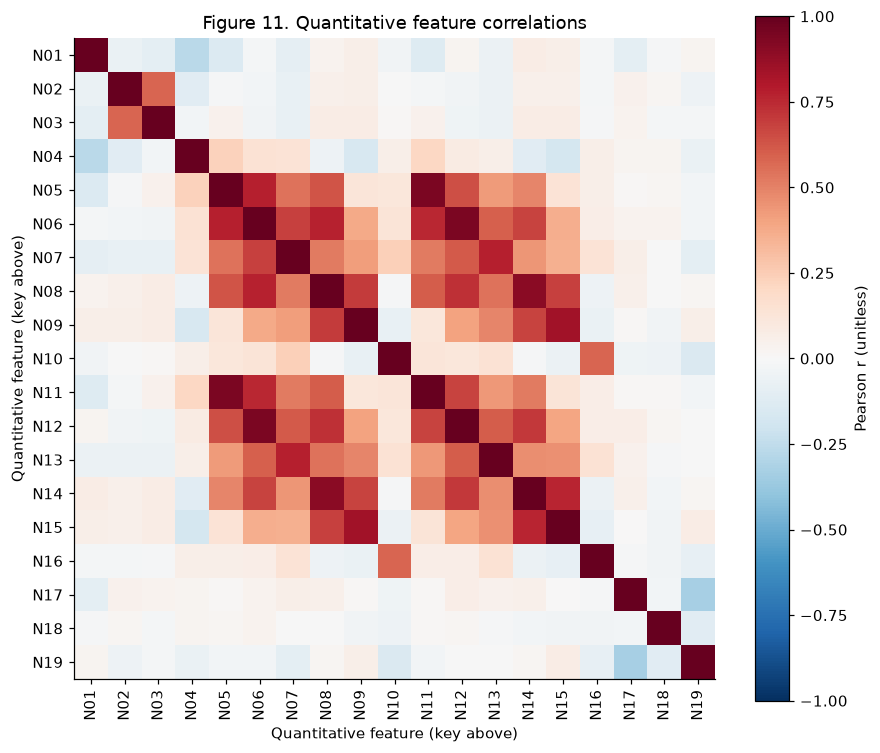

Interpretation: The strongest cross-semester associations show repeated measurement of similar academic activity; remove unavailable semester snapshots first, then recheck dependence among eligible enrollment predictors.
            feature_a             feature_b      r
CU 1st sem (credited) CU 2nd sem (credited) 0.9448
CU 1st sem (enrolled) CU 2nd sem (enrolled) 0.9426
CU 1st sem (approved) CU 2nd sem (approved) 0.9040
   CU 1st sem (grade)    CU 2nd sem (grade) 0.8372
Baseline numeric correlations:
                                Previous qualification (grade)  Admission grade  Age at enrollment
Previous qualification (grade)                           1.000             0.58             -0.111
Admission grade                                          0.580             1.00             -0.030
Age at enrollment                                       -0.111            -0.03              1.000


In [98]:
corr = df[num].corr()
ids = {c: 'N' + str(i + 1).zfill(2) for i, c in enumerate(num)}
print('Axis key:')
for c in num: print(ids[c], c)
fig, ax = plt.subplots(figsize=(8.2, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(num)), [ids[c] for c in num], rotation=90)
ax.set_yticks(range(len(num)), [ids[c] for c in num])
ax.set(title='Figure 11. Quantitative feature correlations',
       xlabel='Quantitative feature (key above)', ylabel='Quantitative feature (key above)')
fig.colorbar(im, ax=ax, label='Pearson r (unitless)')
plt.tight_layout(); plt.show()
print('Interpretation: The strongest cross-semester associations show repeated '
      'measurement of similar academic activity; remove unavailable semester snapshots '
      'first, then recheck dependence among eligible enrollment predictors.')
pairs = [(short[a], short[b], corr.loc[a, b]) for i, a in enumerate(num)
         for b in num[i+1:] if abs(corr.loc[a, b]) > .8]
print(pd.DataFrame(pairs, columns=['feature_a', 'feature_b', 'r']).round(4).to_string(index=False))
baseline_numeric = ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment']
print('Baseline numeric correlations:')
print(df[baseline_numeric].corr().round(3).to_string())

Four pairs exceed 0.8: credited units across semesters (0.945), enrolled units (0.943), approved units (0.904), and grades (0.837). All are excluded from the enrollment baseline. No eligible continuous enrollment pair exceeds the threshold. This does not prove an absence of multivariable collinearity: in M3/M4, recheck the encoded design matrix, use a reference level for each categorical predictor in an intercept-based linear model, and compare regularized logistic regression. If a separately defined later-semester model is ever built, choose one variable from each redundant pair or use regularization, with decisions made within training folds.


## 6. Leakage check: enforce the enrollment cutoff

**Prediction moment:** when the student first enrolls, before first-semester performance exists. We checked variable names, source definitions, the M1 objective and risks, and the missingness/target patterns. Correlation with the outcome is not itself leakage; lack of availability at prediction time is the issue. The CSV has no per-field timestamps, so uncertain availability is not silently treated as confirmed.

**Exclude all 12 semester snapshots.** Grades, approvals, evaluations and non-evaluated units are future information. First-semester credited/enrolled counts might exist at entry, but these exported semester snapshots are not proven to be the original values, so the baseline excludes them as well; second-semester counts are later by definition.

**Quarantine six fields pending timing evidence:** Debtor, Tuition fees up to date and Scholarship holder can change during study; require an enrollment-date snapshot before including them. Unemployment rate, Inflation rate and GDP need the reference period and publication date to ensure no revised/full-year information unavailable on enrollment day is used; GDP additionally lacks a documented unit. This conservative policy is stricter than merely calling a field socioeconomic.

**Retain 18 candidate predictors:** admission, prior education, course/attendance, enrollment age and demographic fields consistent with the published enrollment description. These still require confirmation that an operational system records the same values at the same moment. Keep outcome labels out of all feature engineering, do not derive missingness from Target, and fit encoding, scaling, rare-category pooling and any resampling only within training folds. Split before model-driven feature selection. Exact duplicates were checked; the file has no student identifier or dates to verify repeated-person or temporal independence, which remains a limitation.


In [99]:
quarantine = ['Debtor', 'Tuition fees up to date', 'Scholarship holder',
              'Unemployment rate', 'Inflation rate', 'GDP']
excluded = semester + quarantine
eligible = [c for c in df if c not in excluded + ['Target']]
assert len(eligible) == 18 and len(excluded) == 18
assert 'Target' not in eligible
print('Eligible enrollment candidate columns:')
for c in eligible: print('  ' + c)
print('Excluded from baseline:', len(excluded), 'columns')
X_enrollment = df[eligible].copy()
y = df['Target'].copy()
print('Baseline shape:', X_enrollment.shape, '; target classes:', sorted(y.unique()))

Eligible enrollment candidate columns:
  Marital status
  Application mode
  Application order
  Course
  Daytime/evening attendance
  Previous qualification
  Previous qualification (grade)
  Nacionality
  Mother's qualification
  Father's qualification
  Mother's occupation
  Father's occupation
  Admission grade
  Displaced
  Educational special needs
  Gender
  Age at enrollment
  International
Excluded from baseline: 18 columns
Baseline shape: (4424, 18) ; target classes: ['Dropout', 'Enrolled', 'Graduate']


## 7. Metric commitment

**Optimize Dropout-class F2 in M4**, treating Dropout as positive and Enrolled/Graduate as non-Dropout only for this evaluation score. The predictive task remains three-class classification. F2 = 5PR / (4P + R), where P is dropout precision and R is dropout recall. In count form, F2 = 5TP / (5TP + 4FN + FP). This weights recall more heavily than precision, matching M1's stated priority: a missed future dropout loses a chance for timely help, while false alerts still consume adviser capacity (Boyett and Etzler, *Proposal*, sec. 6).

Beta=2 is a declared project choice, not a measured four-to-one monetary harm ratio. Report dropout precision, recall, the alert count/rate, macro-F1 and the full three-class confusion matrix alongside F2. Macro-F1 guards against ignoring Enrolled, the smallest class. Accuracy is secondary: always predicting Graduate gives approximately 49.93% accuracy but zero dropout recall. F2 alone is also insufficient: alerting on everybody produces a nontrivial F2, so compare that baseline and check whether precision/workload is useful.

Select model settings and any dropout probability threshold using stratified cross-validation on training data only. If thresholding is used, predict Dropout when its probability exceeds the chosen threshold; otherwise choose the larger of the Enrolled and Graduate probabilities. Fix this rule before the final test. Choose thresholds maximizing cross-validated dropout F2, break ties with higher precision, and report workload rather than inventing an adviser-capacity limit. Use the held-out split once and report uncertainty; a future institutional cohort remains the stronger validation.


In [100]:
from sklearn.metrics import fbeta_score, precision_score, recall_score
truth = df.Target.eq('Dropout').to_numpy()
for label, pred in [('Always Graduate', np.zeros(len(df), dtype=bool)),
                    ('Alert every student', np.ones(len(df), dtype=bool))]:
    print(label, ': precision=', round(precision_score(truth, pred, zero_division=0), 3),
          'recall=', round(recall_score(truth, pred, zero_division=0), 3),
          'F2=', round(fbeta_score(truth, pred, beta=2, zero_division=0), 3))
print('These are descriptive reference baselines, not trained-model performance.')

Always Graduate : precision= 0.0 recall= 0.0 F2= 0.0
Alert every student : precision= 0.321 recall= 1.0 F2= 0.703
These are descriptive reference baselines, not trained-model performance.


## 8. Five findings with M3 implications

1. Graduate represents 49.93% of records, Dropout 32.12%, and Enrolled 17.95%, so M3 will use a stratified split and preserve all three classes while preparing dropout-F2 and macro-F1 evaluation.
2. Although every column has zero blank/null cells, maternal qualification is unknown for 130 students and their dropout rate is 73.85% versus 30.86% among known records, so M3 will retain explicit unknown categories instead of dropping or mode-filling these students.
3. Age spans 17-70 years and its median is 23 for dropouts versus 19 for graduates, so M3 will retain plausible older students and compare training-fitted robust scaling and nonlinear age effects rather than trim by IQR.
4. Four cross-semester pairs have correlations above 0.8, including credited units at 0.945, so M3 will exclude all 12 semester snapshots for enrollment prediction and recheck collinearity after encoding the eligible features.
5. Six additional fields have unresolved timing or metadata issues, leaving 18 conservative enrollment candidates, so M3 will use an explicit feature allowlist and admit financial-status or macroeconomic fields only after verifying enrollment-time availability.

## Works Cited

Realinho, Valentim, et al. *Predict Students' Dropout and Academic Success*. UCI Machine Learning Repository, 2021, https://doi.org/10.24432/C5MC89. Accessed Oct. 2026. Dataset and variable definitions; CC BY 4.0. Metadata: https://archive.ics.uci.edu/api/dataset?id=697. Numerical findings in this notebook are calculated from the repository's `data/raw/data.csv`; the SHA-256 is printed in the setup output.

**Preparation note:** AI assistance was used to draft code and explanations and execute checks. The team has reviewed the reasoning and metric commitment before submission.
